In [45]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

In [46]:
file_rotterdamXLS =  r"\Users\svenv\OneDrive\Documenten\2DMM30_stochastics_simulation\Simulation_assignment\rotterdam_dataset_02.xlsx"
df_rotterdam = pd.read_excel(file_rotterdamXLS)
df_rotterdam.head()

,Arrival_Date,Vessel_ID,Vessel_Type,Cargo_tons,Berth_Time_hr
0,2022-01-01 10:33:00,V000001,Container,10597,25.5
1,2022-01-01 19:24:00,V000002,Container,12878,19.2
2,2022-01-01 17:29:00,V000003,Container,11917,24.2
3,2022-01-01 06:23:00,V000004,Container,8757,16.7
4,2022-01-01 05:14:00,V000005,Container,27508,21.8


In [47]:
df_rotterdam.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 17870 entries, 0 to 17869
Data columns (total 5 columns):
 #   Column         Non-Null Count  Dtype         
---  ------         --------------  -----         
 0   Arrival_Date   17870 non-null  datetime64[ns]
 1   Vessel_ID      17870 non-null  object        
 2   Vessel_Type    17870 non-null  object        
 3   Cargo_tons     17870 non-null  int64         
 4   Berth_Time_hr  17870 non-null  float64       
dtypes: datetime64[ns](1), float64(1), int64(1), object(2)
memory usage: 698.2+ KB


In [48]:
print(df_rotterdam.duplicated().sum())

0


In [49]:
grouped_type = df_rotterdam.groupby('Vessel_Type')
type_count = grouped_type['Cargo_tons'].describe()
type_count

,count,mean,std,min,25%,50%,75%,max
Vessel_Type,,,,,,,,
Bulk,5133.0,39785.565556,16193.349694,4911.0,27896.0,37853.0,48969.0,144480.0
Container,10420.0,15765.674952,5635.666662,4125.0,11720.0,14809.5,18851.5,56006.0
Tanker,2317.0,51268.459215,15322.487237,19740.0,40182.0,49016.0,60381.0,128221.0


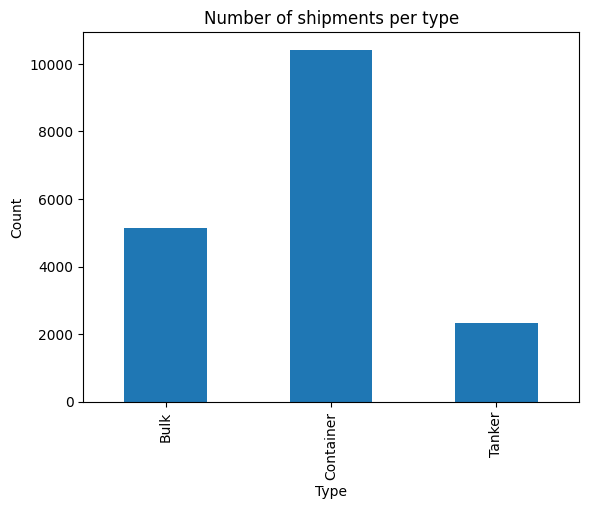

In [50]:
bar_chart_types = type_count.plot( y='count', kind='bar')
plt.ylabel('Count')
plt.xlabel('Type')
plt.title('Number of shipments per type')
bar_chart_types.get_legend().remove()

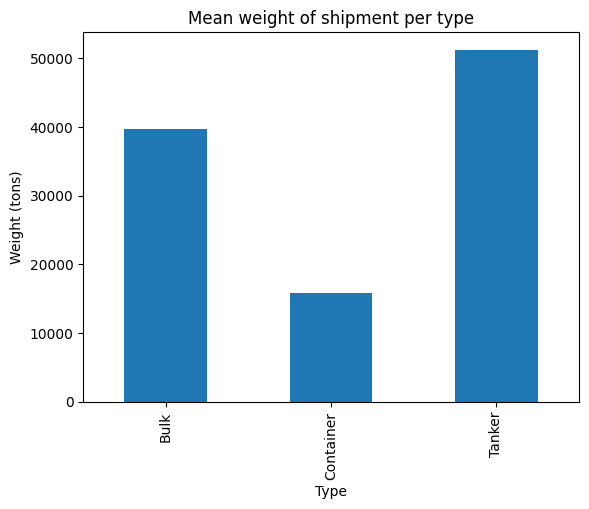

In [51]:
bar_chart_types = type_count.plot( y='mean', kind='bar')
plt.ylabel('Weight (tons)')
plt.xlabel('Type')
plt.title('Mean weight of shipment per type')
bar_chart_types.get_legend().remove()

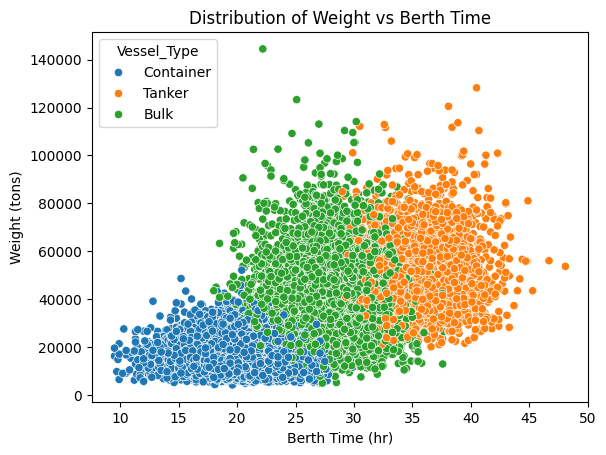

In [52]:
sns.scatterplot(data=df_rotterdam, x='Berth_Time_hr', y='Cargo_tons', hue='Vessel_Type')
plt.xlabel('Berth Time (hr)')
plt.ylabel('Weight (tons)')
plt.title('Distribution of Weight vs Berth Time');

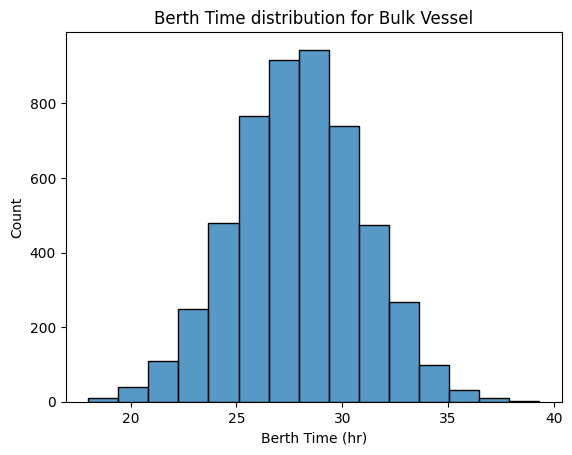

In [53]:
sns.histplot(data=df_rotterdam[df_rotterdam['Vessel_Type'] == 'Bulk'], x='Berth_Time_hr', bins=15)
plt.xlabel('Berth Time (hr)')
plt.title('Berth Time distribution for Bulk Vessel');

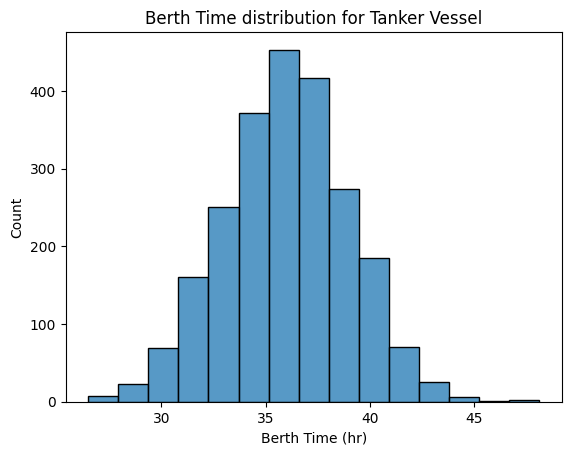

In [54]:
sns.histplot(data=df_rotterdam[df_rotterdam['Vessel_Type'] == 'Tanker'], x='Berth_Time_hr', bins=15)
plt.xlabel('Berth Time (hr)')
plt.title('Berth Time distribution for Tanker Vessel');

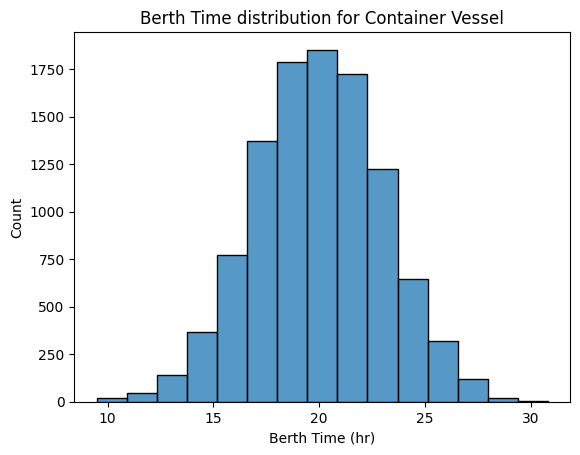

In [55]:
sns.histplot(data=df_rotterdam[df_rotterdam['Vessel_Type'] == 'Container'], x='Berth_Time_hr', bins=15)
plt.xlabel('Berth Time (hr)')
plt.title('Berth Time distribution for Container Vessel');

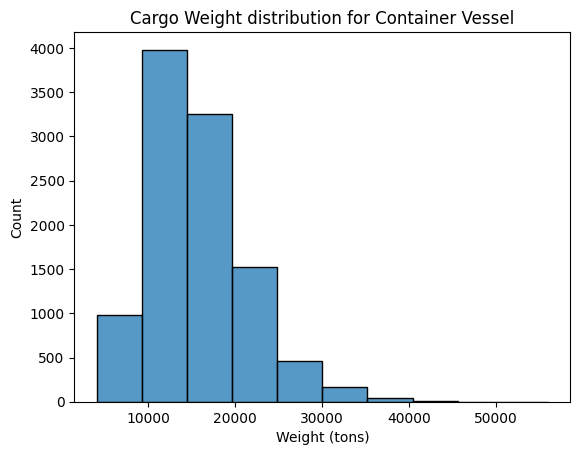

In [56]:
sns.histplot(data=df_rotterdam[df_rotterdam['Vessel_Type'] == 'Container'], x='Cargo_tons', bins=10)
plt.xlabel('Weight (tons)')
plt.title('Cargo Weight distribution for Container Vessel');

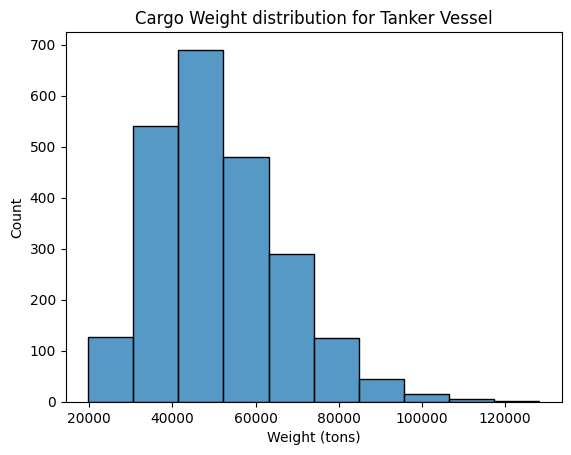

In [57]:
sns.histplot(data=df_rotterdam[df_rotterdam['Vessel_Type'] == 'Tanker'], x='Cargo_tons', bins=10)
plt.xlabel('Weight (tons)')
plt.title('Cargo Weight distribution for Tanker Vessel');

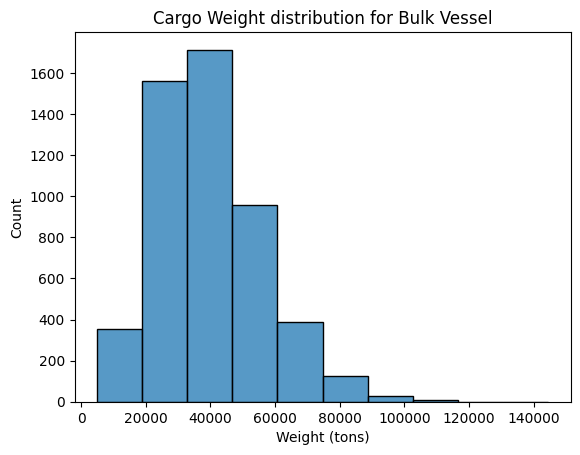

In [58]:
sns.histplot(data=df_rotterdam[df_rotterdam['Vessel_Type'] == 'Bulk'], x='Cargo_tons', bins=10)
plt.xlabel('Weight (tons)')
plt.title('Cargo Weight distribution for Bulk Vessel');

In [59]:
df_months = df_rotterdam.copy()
df_months['YearMonth'] = df_rotterdam['Arrival_Date'].dt.strftime('%Y-%m')
df_months.head()

,Arrival_Date,Vessel_ID,Vessel_Type,Cargo_tons,Berth_Time_hr,YearMonth
0,2022-01-01 10:33:00,V000001,Container,10597,25.5,2022-01
1,2022-01-01 19:24:00,V000002,Container,12878,19.2,2022-01
2,2022-01-01 17:29:00,V000003,Container,11917,24.2,2022-01
3,2022-01-01 06:23:00,V000004,Container,8757,16.7,2022-01
4,2022-01-01 05:14:00,V000005,Container,27508,21.8,2022-01


In [60]:
df_month = df_months.groupby('YearMonth')
df_month_weight = df_month['Cargo_tons'].sum()
df_month_weight = df_month_weight.reset_index()
df_month_weight.head()

,YearMonth,Cargo_tons
0,2022-01,12035278
1,2022-02,10603999
2,2022-03,13384108
3,2022-04,12105041
4,2022-05,14872755


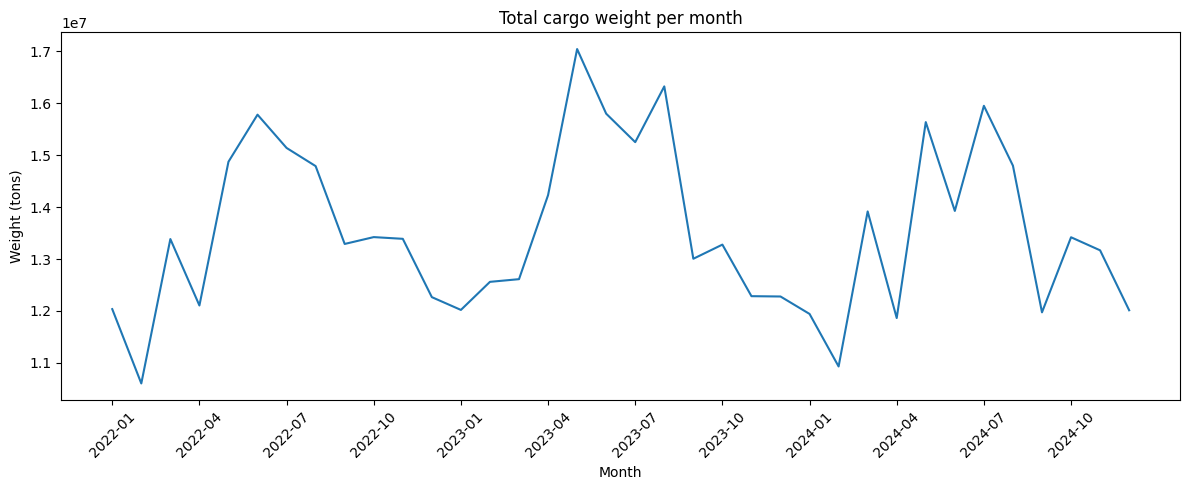

In [61]:
fig, ax = plt.subplots(figsize=(12, 5))
sns.lineplot(data = df_month_weight, x= 'YearMonth', y='Cargo_tons', ax=ax)
plt.title('Total cargo weight per month')
plt.ylabel('Weight (tons)')
plt.xlabel('Month')
ax.set_xticks(ax.get_xticks()[::3])
plt.xticks(rotation=45)
plt.tight_layout();

In [62]:
df_rotterdam.head()

,Arrival_Date,Vessel_ID,Vessel_Type,Cargo_tons,Berth_Time_hr
0,2022-01-01 10:33:00,V000001,Container,10597,25.5
1,2022-01-01 19:24:00,V000002,Container,12878,19.2
2,2022-01-01 17:29:00,V000003,Container,11917,24.2
3,2022-01-01 06:23:00,V000004,Container,8757,16.7
4,2022-01-01 05:14:00,V000005,Container,27508,21.8


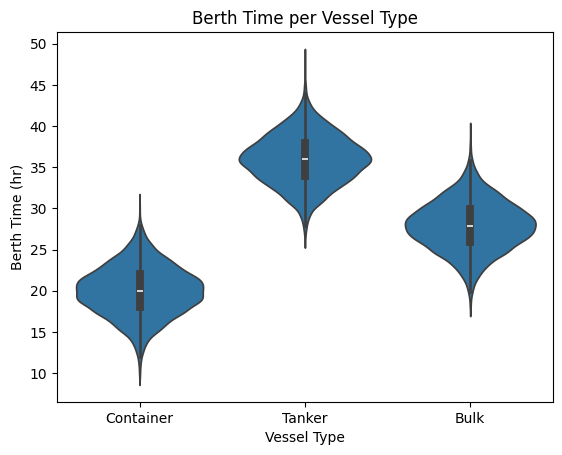

In [63]:
sns.violinplot(data=df_rotterdam, x='Vessel_Type', y='Berth_Time_hr')
plt.title('Berth Time per Vessel Type')
plt.ylabel('Berth Time (hr)')
plt.xlabel('Vessel Type');

In [64]:
df_month.head()

,Arrival_Date,Vessel_ID,Vessel_Type,Cargo_tons,Berth_Time_hr,YearMonth
0,2022-01-01 10:33:00,V000001,Container,10597,25.5,2022-01
1,2022-01-01 19:24:00,V000002,Container,12878,19.2,2022-01
2,2022-01-01 17:29:00,V000003,Container,11917,24.2,2022-01
3,2022-01-01 06:23:00,V000004,Container,8757,16.7,2022-01
4,2022-01-01 05:14:00,V000005,Container,27508,21.8,2022-01
...,...,...,...,...,...,...
17444,2024-12-01 15:18:00,V017445,Container,7118,24.6,2024-12
17445,2024-12-01 02:08:00,V017446,Container,9279,23.3,2024-12
17446,2024-12-01 07:11:00,V017447,Container,11553,18.0,2024-12
17447,2024-12-01 02:51:00,V017448,Container,15713,18.4,2024-12


In [65]:
df_month_shipments = df_month['Vessel_ID'].size()
df_month_shipments = df_month_shipments.reset_index()
df_month_shipments.head()

,YearMonth,Vessel_ID
0,2022-01,454
1,2022-02,394
2,2022-03,512
3,2022-04,443
4,2022-05,547


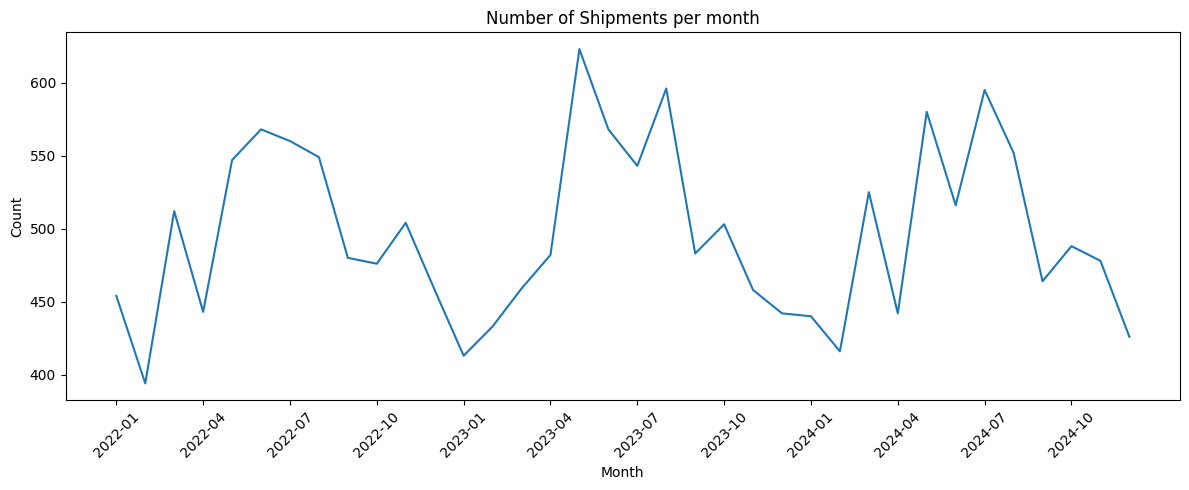

In [66]:
fig, ax = plt.subplots(figsize=(12, 5))
sns.lineplot(data = df_month_shipments, x= 'YearMonth', y='Vessel_ID', ax=ax)
plt.title('Number of Shipments per month')
plt.ylabel('Count')
plt.xlabel('Month')
ax.set_xticks(ax.get_xticks()[::3])
plt.xticks(rotation=45)
plt.tight_layout();

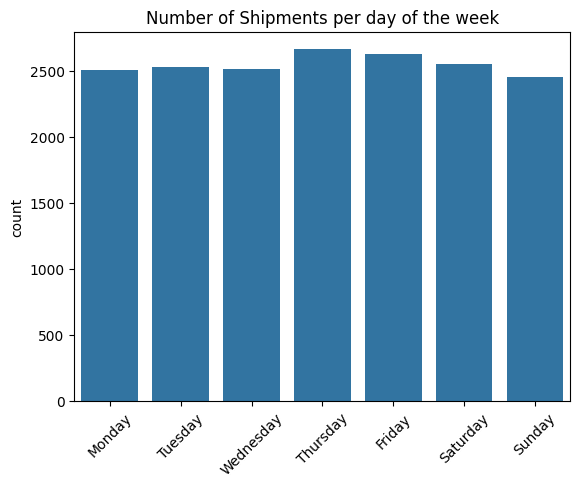

In [67]:
order = ['Monday', 'Tuesday', 'Wednesday','Thursday', 'Friday', 'Saturday', 'Sunday']

df_day = df_rotterdam.copy()
df_day['Day_of_Week'] = df_day['Arrival_Date'].dt.day_name()
df_day_count = df_day.groupby('Day_of_Week')
day_data = df_day_count['Vessel_ID'].describe()
sns.barplot(data=day_data, y='count', x='Day_of_Week', order=order)
plt.title('Number of Shipments per day of the week')
plt.xlabel('')
plt.xticks(rotation = 45);